<a href="https://colab.research.google.com/github/ch1fir/AI_Product_Analytics_Assistant/blob/main/AI_Product_Analytics_Assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# AI Product Analytics Assistant

### Лабораторна робота №4
**AI-підкріплена дата-аналітика: побудова власного аналітичного асистента**

## Мета проєкту

Розробити універсального AI-асистента для автоматизованого аналізу даних із CSV та Excel-файлів за допомогою Python, Pandas і Groq API.

## Реалізовані функції

1. **Automated EDA** — автоматичний розвідувальний аналіз даних, статистика, перевірка якості, візуалізації та AI-інтерпретація.

2. **Hypothesis Generation** — створення 5–10 аналітичних гіпотез на основі розрахованих показників із поясненнями та способами перевірки.

3. **Executive Summary** — автоматичне формування управлінського звіту з ключовими спостереженнями, ризиками та рекомендаціями.

## Використані технології

- Python
- Pandas, NumPy
- Matplotlib
- Google Colab
- Groq API
- LLM: openai/gpt-oss-20b

## Тестування

Асистент протестовано на двох датасетах:

- Online Retail — 541 909 записів.
- Hollywood's Most Profitable Stories — 74 записи.

## Як запустити

1. Відкрити Notebook у Google Colab.
2. Створити Groq API-ключ.
3. Додати його до Colab Secrets під назвою GROQ_API_KEY.
4. Надати Notebook доступ до секрету.
5. Запустити комірки послідовно.
6. Завантажити власний CSV або XLSX-файл.

## Обмеження

AI може припускатися неточностей під час інтерпретації статистики. Результати потребують критичної перевірки аналітиком.

Прототип призначений для структурованих табличних даних і не гарантує сумісності з усіма можливими форматами файлів.


In [47]:
%pip -q install pandas numpy matplotlib openpyxl groq

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from pathlib import Path
from io import BytesIO


In [49]:
# Користувач завантажує власний файл
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Завантажте один CSV або Excel-файл.")

filename, content = next(iter(uploaded.items()))
extension = Path(filename).suffix.lower()

# Автоматично визначаємо формат
if extension == ".csv":
    df = pd.read_csv(BytesIO(content))
elif extension == ".xlsx":
    df = pd.read_excel(BytesIO(content))
else:
    raise ValueError("Підтримуються файли CSV та XLSX.")

# Перевіряємо дані
if df.empty:
    raise ValueError("Файл не містить даних.")

print("Файл:", filename)
print("Кількість рядків:", df.shape[0])
print("Кількість колонок:", df.shape[1])

display(df.head())

print("\nТипи даних:")
display(df.dtypes)

print("\nПропущені значення:")
display(df.isnull().sum())


Saving Online Retail.xlsx to Online Retail (1).xlsx
Файл: Online Retail (1).xlsx
Кількість рядків: 541909
Кількість колонок: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Типи даних:


,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object



Пропущені значення:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [50]:

def auto_eda(data):
    print("=== AUTOMATED DATA ANALYSIS ===")

    # 1. Основна інформація
    print("\n1. Розмір датасету")
    print(f"Рядків: {data.shape[0]}")
    print(f"Колонок: {data.shape[1]}")

    # 2. Типи колонок
    print("\n2. Типи даних")
    display(data.dtypes.to_frame(name="Data Type"))

    # 3. Пропущені значення
    print("\n3. Пропущені значення")

    missing = pd.DataFrame({
        "Missing Count": data.isnull().sum(),
        "Missing %": (
            data.isnull().mean() * 100
        ).round(2)
    })

    display(missing)

    # 4. Дублікати
    print("\n4. Потенційні дублікати")
    print("Повністю однакових рядків:",
          data.duplicated().sum())

    # 5. Числові характеристики
    print("\n5. Числові характеристики")

    numeric = data.select_dtypes(include="number")

    # Не аналізуємо ідентифікатори як метрики
    numeric = numeric.loc[:, [
        col for col in numeric.columns
        if not col.lower().endswith("id")
    ]]

    if not numeric.empty:
        display(numeric.describe().T)
    else:
        print("Числові метрики відсутні.")

    # 6. Категоріальні змінні
    print("\n6. Категоріальні змінні")

    categorical = data.select_dtypes(
        include=["object", "category", "string"]
    )

    for col in categorical.columns:
        print(f"\nКолонка: {col}")
        print("Унікальних значень:",
              data[col].nunique())

        display(data[col].value_counts().head(5))

    print("\n=== ANALYSIS COMPLETED ===")


# Запускаємо функцію
auto_eda(df)


=== AUTOMATED DATA ANALYSIS ===

1. Розмір датасету
Рядків: 541909
Колонок: 8

2. Типи даних


,Data Type
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object



3. Пропущені значення


,Missing Count,Missing %
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00



4. Потенційні дублікати
Повністю однакових рядків: 5268

5. Числові характеристики


,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0


... (5 outputs left out)

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2369
REGENCY CAKESTAND 3 TIER,2200
JUMBO BAG RED RETROSPOT,2159
PARTY BUNTING,1727
LUNCH BAG RED RETROSPOT,1638



Колонка: Country
Унікальних значень: 38


,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533



=== ANALYSIS COMPLETED ===


In [51]:
def inspect_numeric_anomalies(data):

    print("=== NUMERIC ANOMALY DETECTION ===")

    numeric_cols = data.select_dtypes(
        include="number"
    ).columns

    results = []

    for col in numeric_cols:

        # Виключаємо типові ідентифікатори
        if col.lower().endswith(("id", "code", "no")):
            continue

        values = data[col].dropna()

        if values.empty:
            continue

        negative = (values < 0).sum()
        zero = (values == 0).sum()

        # Метод міжквартильного розмаху (IQR)
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = (
            (values < lower) | (values > upper)
        ).sum()

        results.append({
            "Column": col,
            "Negative values": negative,
            "Zero values": zero,
            "Potential outliers": outliers,
            "Min": values.min(),
            "Max": values.max()
        })

    if results:
        display(pd.DataFrame(results))
    else:
        print("Числових метрик не знайдено.")


inspect_numeric_anomalies(df)


=== NUMERIC ANOMALY DETECTION ===


,Column,Negative values,Zero values,Potential outliers,Min,Max
0,Quantity,10624,0,58619,-80995.00,80995.0
1,UnitPrice,2,2515,39627,-11062.06,38970.0


=== AUTOMATED DATA VISUALIZATION ===


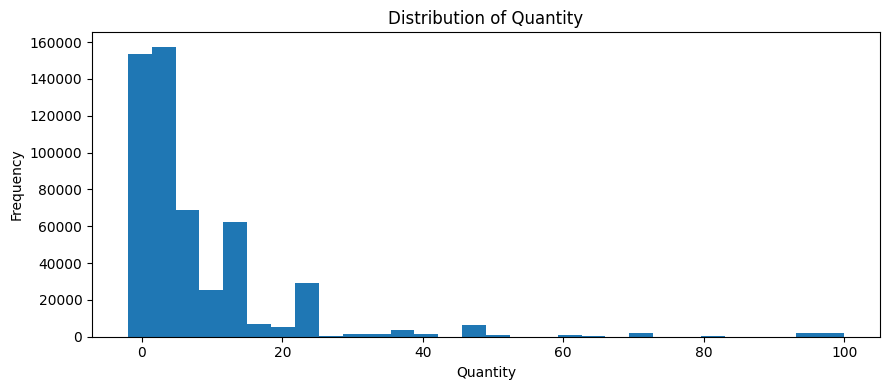

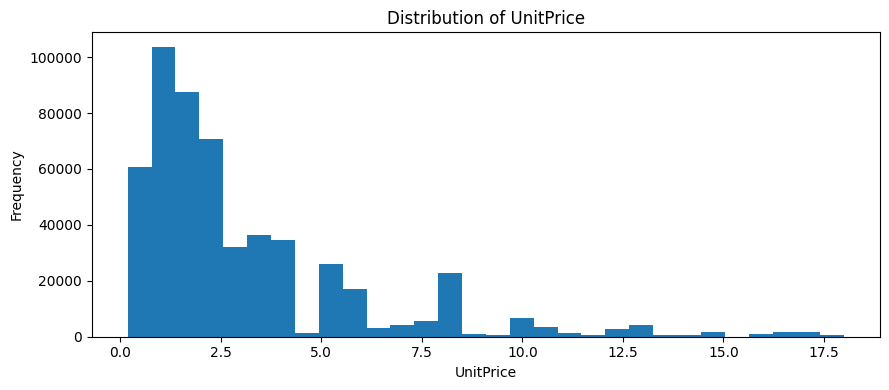

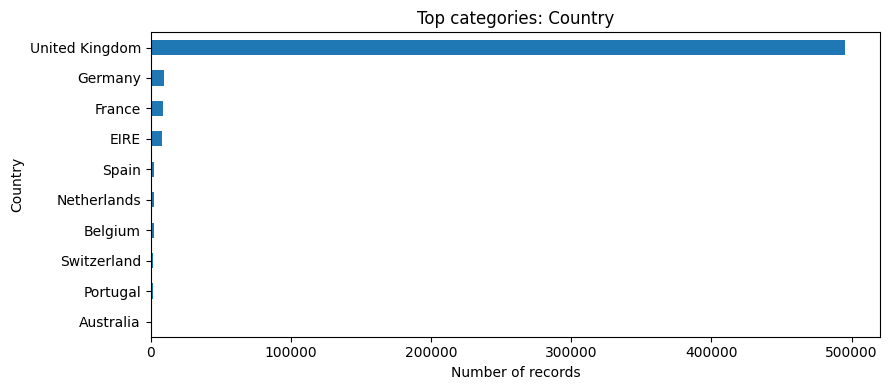

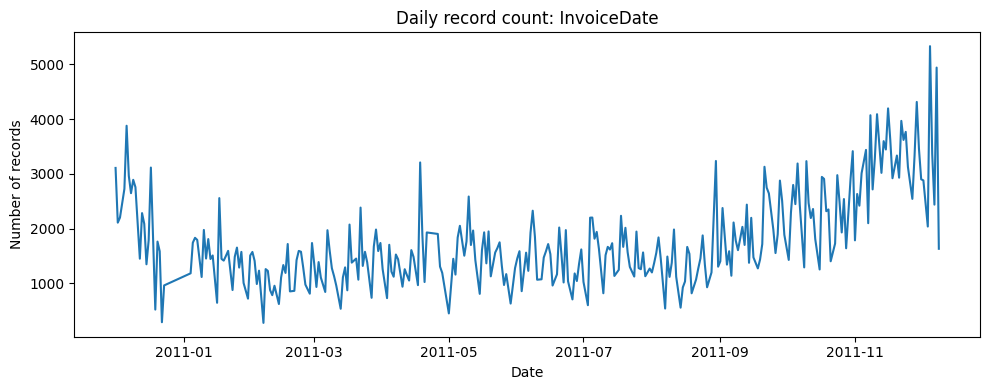

=== VISUALIZATION COMPLETED ===


In [52]:
def auto_visualize(data):

    print("=== AUTOMATED DATA VISUALIZATION ===")

    # 1. Числові змінні
    numeric = data.select_dtypes(include="number")

    numeric_cols = [
        col for col in numeric.columns
        if not col.lower().endswith(("id", "code", "no"))
    ]

    for col in numeric_cols[:4]:

        values = data[col].dropna()

        if values.empty:
            continue

        # Обмежуємо діапазон для кращої читабельності
        lower = values.quantile(0.01)
        upper = values.quantile(0.99)

        filtered = values[
            (values >= lower) & (values <= upper)
        ]

        plt.figure(figsize=(9, 4))
        plt.hist(filtered, bins=30)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

    # 2. Категоріальні змінні
    categorical = data.select_dtypes(
        include=["object", "category", "string"]
    )

    suitable_cols = [
        col for col in categorical.columns
        if 2 <= data[col].nunique() <= 50
        and not col.lower().endswith(("id", "code", "no"))
    ]

    for col in suitable_cols[:3]:

        counts = data[col].value_counts().head(10)

        plt.figure(figsize=(9, 4))
        counts.sort_values().plot(kind="barh")
        plt.title(f"Top categories: {col}")
        plt.xlabel("Number of records")
        plt.tight_layout()
        plt.show()

    # 3. Динаміка за датами
    date_cols = data.select_dtypes(
        include="datetime"
    ).columns

    if len(date_cols) > 0:

        col = date_cols[0]

        daily = (
            data.dropna(subset=[col])
            .groupby(data[col].dt.date)
            .size()
        )

        if not daily.empty:
            plt.figure(figsize=(10, 4))
            daily.plot(kind="line")
            plt.title(f"Daily record count: {col}")
            plt.xlabel("Date")
            plt.ylabel("Number of records")
            plt.tight_layout()
            plt.show()

    print("=== VISUALIZATION COMPLETED ===")


auto_visualize(df)


In [53]:
import json

def build_ai_context(data):

    if data.empty:
        raise ValueError("Датасет порожній.")

    summary = {
        "dataset": {
            "rows": int(data.shape[0]),
            "columns": int(data.shape[1]),
            "duplicates": int(data.duplicated().sum())
        },
        "missing_values": {},
        "numeric_statistics": {},
        "categorical_statistics": {},
        "date_columns": {}
    }

    # 1. Пропущені значення
    for col in data.columns:
        summary["missing_values"][str(col)] = {
            "count": int(data[col].isna().sum()),
            "percent": round(
                float(data[col].isna().mean() * 100), 2
            )
        }

    # 2. Числові змінні
    numeric = data.select_dtypes(include="number")

    for col in numeric.columns:

        if str(col).lower().endswith(
            ("id", "code", "no")
        ):
            continue

        values = numeric[col].dropna()

        if values.empty:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        outliers = (
            (values < q1 - 1.5 * iqr) |
            (values > q3 + 1.5 * iqr)
        ).sum()

        summary["numeric_statistics"][str(col)] = {
            "mean": round(float(values.mean()), 2),
            "median": round(float(values.median()), 2),
            "min": float(values.min()),
            "max": float(values.max()),
            "negative_count": int((values < 0).sum()),
            "zero_count": int((values == 0).sum()),
            "potential_outliers": int(outliers)
        }

    # 3. Категоріальні змінні
    categorical = data.select_dtypes(
        include=["object", "category", "string"]
    )

    for col in categorical.columns:

        if str(col).lower().endswith(
            ("id", "code", "no")
        ):
            continue

        unique_count = data[col].nunique()

        if 2 <= unique_count <= 50:

            top_values = (
                data[col].value_counts().head(5)
            )

            summary["categorical_statistics"][str(col)] = {
                "unique_values": int(unique_count),
                "top_categories": {
                    str(k): int(v)
                    for k, v in top_values.items()
                }
            }

    # 4. Колонки з датами
    date_cols = data.select_dtypes(
        include="datetime"
    ).columns

    for col in date_cols:

        dates = data[col].dropna()

        if not dates.empty:
            summary["date_columns"][str(col)] = {
                "min_date": str(dates.min()),
                "max_date": str(dates.max())
            }

    return summary


# Формуємо структурований звіт
ai_context = build_ai_context(df)

# Переглядаємо результат
print(json.dumps(
    ai_context,
    indent=2,
    ensure_ascii=False
))


{
  "dataset": {
    "rows": 541909,
    "columns": 8,
    "duplicates": 5268
  },
  "missing_values": {
    "InvoiceNo": {
      "count": 0,
      "percent": 0.0
    },
    "StockCode": {
      "count": 0,
      "percent": 0.0
    },
    "Description": {
      "count": 1454,
      "percent": 0.27
    },
    "Quantity": {
      "count": 0,
      "percent": 0.0
    },
    "InvoiceDate": {
      "count": 0,
      "percent": 0.0
    },
    "UnitPrice": {
      "count": 0,
      "percent": 0.0
    },
    "CustomerID": {
      "count": 135080,
      "percent": 24.93
    },
    "Country": {
      "count": 0,
      "percent": 0.0
    }
  },
  "numeric_statistics": {
    "Quantity": {
      "mean": 9.55,
      "median": 3.0,
      "min": -80995.0,
      "max": 80995.0,
      "negative_count": 10624,
      "zero_count": 0,
      "potential_outliers": 58619
    },
    "UnitPrice": {
      "mean": 4.61,
      "median": 2.08,
      "min": -11062.06,
      "max": 38970.0,
      "negative_count": 2,

In [54]:
from groq import Groq
from google.colab import userdata

# Отримуємо ключ із Colab Secrets
api_key = userdata.get("GROQ_API_KEY")

if not api_key:
    raise ValueError("Додайте GROQ_API_KEY у Secrets.")

# Підключаємо Groq
client = Groq(api_key=api_key)

# Обираємо модель
MODEL = "openai/gpt-oss-20b"

# Тестовий запит
response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {
            "role": "user",
            "content": (
                "Привіт! Поясни одним реченням "
                "українською, що таке продуктова аналітика."
            )
        }
    ],
    max_completion_tokens=200
)

print("Groq працює!")
print(response.choices[0].message.content)


Groq працює!
Продуктова аналітика — це процес збору, аналізу й інтерпретації даних про використання продукту з метою прийняття обґрунтованих рішень щодо його удосконалення та розвитку.


In [55]:
import json

def interpret_eda(summary):

    instructions = """
    Ти — досвідчений продуктовий аналітик,
    який спеціалізується на дослідженні даних,
    продуктових метриках та бізнес-аналітиці.

    Твоє завдання — проаналізувати наданий JSON
    зі статистичними характеристиками датасету
    та сформувати професійний аналітичний звіт.

    === ПРАВИЛА АНАЛІЗУ ===

    1. Використовуй виключно інформацію та числові
       показники, наявні в переданому JSON.

    2. Не вигадуй додаткових метрик, статистичних
       показників, фактів або результатів аналізу.

    3. Чітко відокремлюй підтверджені даними факти
       від припущень, інтерпретацій та гіпотез.

    4. Не плутай кореляцію з причинно-наслідковим
       зв'язком. Не стверджуй, що певний фактор
       спричинив зміну метрики без доказів.

    5. Не називай статистичні викиди помилками
       без додаткових доказів. Викиди можуть бути
       реальними та важливими спостереженнями.

    6. Враховуй пропущені значення, потенційні
       дублікати та інші обмеження якості даних.

    7. Не роби висновків про виручку, прибуток,
       конверсію, кількість продажів або інші
       бізнес-метрики, якщо вони не були
       розраховані та передані в JSON.

    8. Не ототожнюй кількість рядків датасету
       з кількістю замовлень, транзакцій
       або унікальних користувачів.

       Один рядок може відповідати окремому
       товару, події або іншому спостереженню.

       Якщо одиниця спостереження невідома,
       використовуй термін "рядок" або "запис".

    9. Не рекомендуй автоматично видаляти
       дублікати, пропущені значення або викиди.

       Спочатку запропонуй перевірити їхню
       природу та можливий вплив на результати.

    10. Не рекомендуй відновлювати або
        заповнювати відсутні ідентифікатори
        користувачів без надійного джерела
        інформації.

    11. Пам'ятай, що метод IQR визначає
        потенційні викиди на основі квартилів
        та міжквартильного розмаху, а не
        відхилення від середнього значення.

    12. Не обчислюй нові відсотки або метрики
        самостійно. Використовуй тільки
        показники, розраховані Python.

        Якщо необхідний показник відсутній,
        зазнач, що його потрібно розрахувати.

    13. Не роби висновків про сезонність,
        зростання або падіння показників,
        якщо JSON не містить необхідної
        часової статистики.

    14. Не припускай, що від'ємні або нульові
        значення обов'язково є помилками.

        Вони можуть відповідати поверненням,
        коригуванням або особливостям
        бізнес-процесів.

    15. Формулюй конкретні та практичні
        рекомендації, які можна перевірити
        за допомогою додаткового аналізу.

    16. Якщо інформації недостатньо для
        обґрунтованого висновку, прямо
        повідомляй про це.

    17. Не стверджуй, що було проведено
        аналіз, якого немає в переданому JSON.

    === СТРУКТУРА АНАЛІТИЧНОГО ЗВІТУ ===

    1. Dataset Overview

       - Коротко опиши структуру датасету.
       - Вкажи кількість рядків і колонок.
       - Зазнач часовий діапазон, якщо він є.
       - Поясни, які типи даних представлені,
         якщо це можна визначити з JSON.

    2. Data Quality Assessment

       - Проаналізуй пропущені значення.
       - Оціни кількість потенційних дублікатів.
       - Зверни увагу на від'ємні та нульові
         значення.
       - Поясни значення потенційних викидів.
       - Зазнач, які проблеми потребують
         додаткової перевірки.

    3. Key Analytical Findings

       - Виділи найбільш важливі статистичні
         спостереження.
       - Поясни відмінності між середнім
         значенням і медіаною, якщо вони є.
       - Проаналізуй доступні категоріальні
         показники.
       - Поясни можливе бізнес-значення
         виявлених закономірностей.
       - Не представляй припущення як факти.

    4. Potential Risks and Limitations

       - Опиши обмеження датасету.
       - Поясни, як пропуски, дублікати
         та викиди можуть впливати
         на майбутній аналіз.
       - Зазнач метрики, які неможливо
         коректно оцінити з наявних даних.
       - Вкажи, які висновки потребують
         додаткового підтвердження.

    5. Recommended Next Steps

       - Запропонуй конкретні наступні
         аналітичні дії.
       - Визнач, які проблеми якості даних
         потрібно перевірити насамперед.
       - Запропонуй напрями сегментації
         або додаткових досліджень,
         якщо структура даних це дозволяє.
       - Рекомендації мають бути пов'язані
         з фактичними результатами аналізу.

    === ФОРМАТ ВІДПОВІДІ ===

    - Відповідай українською мовою.
    - Використовуй професійний,
      але зрозумілий стиль.
    - Дотримуйся структури з п'яти розділів.
    - Використовуй Markdown для заголовків,
      таблиць та списків, коли це доречно.
    - Уникай загальних фраз без аналітичної
      цінності.
    - Віддавай перевагу конкретним висновкам,
      підтвердженим даними.
    - Не повторюй однакові висновки
      в декількох розділах.
    """

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": instructions
            },
            {
                "role": "user",
                "content": json.dumps(
                    summary,
                    ensure_ascii=False
                )
            }
        ],
        temperature=0.2,
        max_completion_tokens=3000
    )

    return response.choices[0].message.content


# Запускаємо AI-інтерпретацію
eda_interpretation = interpret_eda(ai_context)

print("=== AI DATA ANALYSIS REPORT ===")
print(eda_interpretation)


=== AI DATA ANALYSIS REPORT ===
## 1. Dataset Overview  

| Параметр | Значення |
|----------|----------|
| Кількість рядків | **541 909** |
| Кількість колонок | **8** |
| Кількість дублікатів | **5 268** (≈ 0.97 %) |
| Часовий діапазон | **2010‑12‑01 08:26:00** – **2011‑12‑09 12:50:00** |
| Типи даних (за припущенням) | `InvoiceNo` – текст/число, `StockCode` – текст/число, `Description` – текст, `Quantity` – ціле число, `InvoiceDate` – дата/час, `UnitPrice` – десяткове число, `CustomerID` – ціле число, `Country` – текст |

> **Примітка**


In [56]:

def build_hypothesis_context(data):

    if data.empty:
        raise ValueError("Датасет порожній.")

    result = {
        "segment_comparisons": {},
        "monthly_record_counts": {}
    }

    # Числові метрики
    numeric_cols = [
        col for col in data.select_dtypes(
            include="number"
        ).columns
        if not str(col).lower().endswith(
            ("id", "code", "no")
        )
    ]

    # Категоріальні змінні
    categorical_cols = [
        col for col in data.select_dtypes(
            include=["object", "category", "string"]
        ).columns
        if 2 <= data[col].nunique() <= 50
        and not str(col).lower().endswith(
            ("id", "code", "no")
        )
    ]

    # Порівняння сегментів
    for col in categorical_cols[:3]:

        top_categories = (
            data[col].value_counts().head(10).index
        )

        rows = []

        for category in top_categories:

            group = data[data[col] == category]

            row = {
                "category": str(category),
                "row_count": int(len(group)),
                "row_share_percent": round(
                    len(group) / len(data) * 100, 2
                )
            }

            for metric in numeric_cols[:4]:
                values = group[metric].dropna()

                if not values.empty:
                    row[f"{metric}_median"] = round(
                        float(values.median()), 2
                    )

            rows.append(row)

        result["segment_comparisons"][str(col)] = rows

    # Динаміка кількості записів за місяцями
    date_cols = data.select_dtypes(
        include="datetime"
    ).columns

    for col in date_cols[:2]:

        monthly = (
            data[col].dropna()
            .dt.to_period("M")
            .value_counts()
            .sort_index()
        )

        result["monthly_record_counts"][str(col)] = {
            str(month): int(count)
            for month, count in monthly.items()
        }

    return result


# Формуємо додаткові дані для гіпотез
hypothesis_context = build_hypothesis_context(df)

print(json.dumps(
    hypothesis_context,
    indent=2,
    ensure_ascii=False
))


{
  "segment_comparisons": {
    "Country": [
      {
        "category": "United Kingdom",
        "row_count": 495478,
        "row_share_percent": 91.43,
        "Quantity_median": 3.0,
        "UnitPrice_median": 2.1
      },
      {
        "category": "Germany",
        "row_count": 9495,
        "row_share_percent": 1.75,
        "Quantity_median": 10.0,
        "UnitPrice_median": 1.95
      },
      {
        "category": "France",
        "row_count": 8557,
        "row_share_percent": 1.58,
        "Quantity_median": 10.0,
        "UnitPrice_median": 1.79
      },
      {
        "category": "EIRE",
        "row_count": 8196,
        "row_share_percent": 1.51,
        "Quantity_median": 10.0,
        "UnitPrice_median": 2.1
      },
      {
        "category": "Spain",
        "row_count": 2533,
        "row_share_percent": 0.47,
        "Quantity_median": 6.0,
        "UnitPrice_median": 2.08
      },
      {
        "category": "Netherlands",
        "row_count": 2371,
    

In [57]:
import copy
import pandas as pd

def filter_incomplete_months(hypothesis_context, ai_context):

    cleaned = copy.deepcopy(hypothesis_context)

    for col, months in cleaned.get(
        "monthly_record_counts", {}
    ).items():

        date_info = ai_context.get(
            "date_columns", {}
        ).get(col)

        if not date_info:
            continue

        start = pd.to_datetime(date_info["min_date"])
        end = pd.to_datetime(date_info["max_date"])

        # Виключаємо неповний початковий місяць
        if start.day > 1:
            months.pop(str(start.to_period("M")), None)

        # Виключаємо неповний кінцевий місяць
        if end.day < end.days_in_month:
            months.pop(str(end.to_period("M")), None)

    return cleaned


# Контекст без неповних крайніх місяців
validated_hypothesis_context = filter_incomplete_months(
    hypothesis_context,
    ai_context
)

print(json.dumps(
    validated_hypothesis_context["monthly_record_counts"],
    indent=2,
    ensure_ascii=False
))


{
  "InvoiceDate": {
    "2010-12": 42481,
    "2011-01": 35147,
    "2011-02": 27707,
    "2011-03": 36748,
    "2011-04": 29916,
    "2011-05": 37030,
    "2011-06": 36874,
    "2011-07": 39518,
    "2011-08": 35284,
    "2011-09": 50226,
    "2011-10": 60742,
    "2011-11": 84711
  }
}


In [60]:
import copy
import json

def enrich_hypothesis_context(data, context):

    enriched = copy.deepcopy(context)

    # Колонки з найбільшою кількістю пропусків
    missing_cols = sorted(
        [
            col for col in data.columns
            if data[col].isna().any()
        ],
        key=lambda col: data[col].isna().sum(),
        reverse=True
    )[:2]

    # Числові колонки, крім ідентифікаторів
    numeric_cols = [
        col for col in data.select_dtypes(
            include="number"
        ).columns
        if not str(col).lower().endswith(
            ("id", "code", "no")
        )
    ][:3]

    # Доповнюємо статистику кожного сегмента
    for dimension, segments in enriched.get(
        "segment_comparisons", {}
    ).items():

        if dimension not in data.columns:
            continue

        for segment_info in segments:

            category = segment_info["category"]

            segment = data.loc[
                data[dimension] == category
            ]

            if segment.empty:
                continue

            # Частка пропущених значень
            for col in missing_cols:

                segment_info[
                    f"{col}_missing_percent"
                ] = round(
                    segment[col].isna().mean() * 100,
                    2
                )

            # Додаткові числові характеристики
            for col in numeric_cols:

                values = segment[col].dropna()

                if values.empty:
                    continue

                segment_info[
                    f"{col}_negative_percent"
                ] = round(
                    (values < 0).mean() * 100,
                    2
                )

                segment_info[
                    f"{col}_zero_percent"
                ] = round(
                    (values == 0).mean() * 100,
                    2
                )

                segment_info[
                    f"{col}_q25"
                ] = round(
                    float(values.quantile(0.25)),
                    2
                )

                segment_info[
                    f"{col}_q75"
                ] = round(
                    float(values.quantile(0.75)),
                    2
                )

    return enriched


# Збагачуємо вже перевірений контекст
enriched_hypothesis_context = enrich_hypothesis_context(
    df,
    validated_hypothesis_context
)

# Переглядаємо результат
print("=== ENRICHED HYPOTHESIS CONTEXT ===")

for dimension, segments in enriched_hypothesis_context[
    "segment_comparisons"
].items():

    if segments:
        print(json.dumps(
            segments[:2],
            indent=2,
            ensure_ascii=False
        ))


=== ENRICHED HYPOTHESIS CONTEXT ===
[
  {
    "category": "United Kingdom",
    "row_count": 495478,
    "row_share_percent": 91.43,
    "Quantity_median": 3.0,
    "UnitPrice_median": 2.1,
    "CustomerID_missing_percent": 26.96,
    "Description_missing_percent": 0.29,
    "Quantity_negative_percent": 1.86,
    "Quantity_zero_percent": 0.0,
    "Quantity_q25": 1.0,
    "Quantity_q75": 10.0,
    "UnitPrice_negative_percent": 0.0,
    "UnitPrice_zero_percent": 0.5,
    "UnitPrice_q25": 1.25,
    "UnitPrice_q75": 4.13
  },
  {
    "category": "Germany",
    "row_count": 9495,
    "row_share_percent": 1.75,
    "Quantity_median": 10.0,
    "UnitPrice_median": 1.95,
    "CustomerID_missing_percent": 0.0,
    "Description_missing_percent": 0.0,
    "Quantity_negative_percent": 4.77,
    "Quantity_zero_percent": 0.0,
    "Quantity_q25": 5.0,
    "Quantity_q75": 12.0,
    "UnitPrice_negative_percent": 0.0,
    "UnitPrice_zero_percent": 0.02,
    "UnitPrice_q25": 1.25,
    "UnitPrice_q75": 3.

In [61]:
import json

def suggest_hypotheses(hypothesis_context, ai_context):

    # 1. Формуємо перевірені факти за допомогою Python
    facts = {}

    for dimension, segments in hypothesis_context[
        "segment_comparisons"
    ].items():

        for segment in segments:
            fact_id = f"F{len(facts) + 1}"

            facts[fact_id] = {
                "dimension": dimension,
                **segment
            }

    for date_col, months in hypothesis_context[
        "monthly_record_counts"
    ].items():

        for month, count in months.items():
            fact_id = f"F{len(facts) + 1}"

            facts[fact_id] = {
                "date_column": date_col,
                "month": month,
                "row_count": count
            }

    if not facts:
        print("Недостатньо даних для генерації гіпотез.")
        return []

    # 2. Промпт для AI
    instructions = """
    Ти — досвідчений продуктовий аналітик.

    Твоє завдання — запропонувати 5–10
    аналітичних гіпотез на основі JSON
    із перевіреними статистичними фактами.

    === ПРАВИЛА ===

    1. Використовуй виключно передані факти.

    2. Не вигадуй додаткових метрик.

    3. Кожна гіпотеза повинна мати
       конкретне числове обґрунтування.

    4. Для підтвердження гіпотези вкажи
       ID відповідних фактів (F1, F2 тощо).

    5. Не включай нові числа у власні
       текстові пояснення. Числові докази
       будуть додані програмно.

    6. Не плутай кореляцію з причинністю.

    7. Чітко відділяй спостереження
       від можливого пояснення.

    8. Пояснюй, як перевірити кожну гіпотезу.

    9. Не ототожнюй кількість рядків
       із кількістю замовлень або продажів.

    10. Медіана Quantity характеризує
        кількість одиниць на рядок даних,
        а не на ціле замовлення.

    11. Враховуй неповні календарні періоди.
        Не порівнюй неповний місяць із повним
        без відповідного застереження.

    12. Не стверджуй, що причину
        закономірності вже встановлено.

    13. Гіпотези мають бути різноманітними,
        конкретними та практично корисними.

    14. Не формулюй гіпотезу як простий опис уже
        встановленого факту. Кожна гіпотеза має
        містити можливе пояснення закономірності,
        яке можна перевірити.

    15. Не стверджуй, що певне значення є
        найбільшим або найменшим серед усіх
        категорій, якщо передано лише їх частину.

    16. Не називай категорію одноосібним лідером,
        якщо інша категорія має таке саме значення.

    17. Не роби тверджень про збільшення або
        зменшення показника без перевіреного
        числового порівняння.

    18. Не порівнюй безпосередньо повні
        та неповні календарні періоди.

    19. Якщо даних недостатньо для якісної
        гіпотези, не вигадуй її лише для
        досягнення потрібної кількості.

    20. Пріоритет надавай гіпотезам, які
        можуть допомогти ухвалити конкретне
        продуктове або бізнес-рішення.


    === ФОРМАТ ВІДПОВІДІ ===

    Поверни лише JSON-об'єкт із ключем
    "hypotheses".

    Кожна гіпотеза повинна містити:

    - title: коротка назва
    - explanation: можливе пояснення
    - evidence_ids: список ID фактів
    - validation: спосіб перевірки
    - limitation: обмеження висновку

    Усі текстові поля — українською мовою.
    """

    payload = {
        "facts": facts,
        "date_ranges": ai_context.get(
            "date_columns", {}
        )
    }

    # 3. Викликаємо Groq
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": instructions
            },
            {
                "role": "user",
                "content": json.dumps(
                    payload,
                    ensure_ascii=False
                )
            }
        ],
        response_format={"type": "json_object"},
        temperature=0.2,
        max_completion_tokens=4000
    )

    # 4. Перевіряємо структуру відповіді
    result = json.loads(
        response.choices[0].message.content
    )

    hypotheses = result["hypotheses"]

    if not 5 <= len(hypotheses) <= 10:
        raise ValueError(
            "AI повинен повернути 5–10 гіпотез."
        )

    for hypothesis in hypotheses:
        evidence_ids = hypothesis["evidence_ids"]

        if not evidence_ids or any(
            fact_id not in facts
            for fact_id in evidence_ids
        ):
            raise ValueError(
                "AI використав невідомі факти."
            )

    # 5. Виводимо гіпотези
    print("=== AI HYPOTHESIS GENERATION ===")

    for i, hypothesis in enumerate(hypotheses, 1):

        print(f"\nГіпотеза {i}: {hypothesis['title']}")

        print("\nМожливе пояснення:")
        print(hypothesis["explanation"])

        print("\nЧислові докази:")
        for fact_id in hypothesis["evidence_ids"]:
            print(f"- {fact_id}: {facts[fact_id]}")

        print("\nЯк перевірити:")
        print(hypothesis["validation"])

        print("\nОбмеження:")
        print(hypothesis["limitation"])

        print("-" * 50)

    return hypotheses


# Запускаємо генерацію гіпотез
hypotheses = suggest_hypotheses(
    enriched_hypothesis_context,
    ai_context
)


=== AI HYPOTHESIS GENERATION ===

Гіпотеза 1: Високий відсоток рядків у країні пов’язаний із вищим медіанним ціною одиниці

Можливе пояснення:
Країни, що представляють більшу частку даних, мають тенденцію до більш високих медіанних цін одиниць товару

Числові докази:
- F1: {'dimension': 'Country', 'category': 'United Kingdom', 'row_count': 495478, 'row_share_percent': 91.43, 'Quantity_median': 3.0, 'UnitPrice_median': 2.1, 'CustomerID_missing_percent': np.float64(26.96), 'Description_missing_percent': np.float64(0.29), 'Quantity_negative_percent': np.float64(1.86), 'Quantity_zero_percent': np.float64(0.0), 'Quantity_q25': 1.0, 'Quantity_q75': 10.0, 'UnitPrice_negative_percent': np.float64(0.0), 'UnitPrice_zero_percent': np.float64(0.5), 'UnitPrice_q25': 1.25, 'UnitPrice_q75': 4.13}
- F2: {'dimension': 'Country', 'category': 'Germany', 'row_count': 9495, 'row_share_percent': 1.75, 'Quantity_median': 10.0, 'UnitPrice_median': 1.95, 'CustomerID_missing_percent': np.float64(0.0), 'Descript

In [62]:
import json
from IPython.display import Markdown, display

def generate_executive_summary(
    ai_context,
    hypothesis_context
):

    instructions = """
    Ти — досвідчений продуктовий аналітик,
    який готує короткі звіти для керівництва.

    Твоє завдання — сформувати Executive Summary
    на основі переданої статистики датасету.

    === ПРАВИЛА ===

    1. Використовуй тільки інформацію з JSON.

    2. Не вигадуй додаткових чисел,
       бізнес-метрик або причин.

    3. Не обчислюй нові показники самостійно.

    4. Не плутай кількість рядків
       із кількістю замовлень або продажів.

    5. Не називай гіпотези підтвердженими
       фактами без відповідної перевірки.

    6. Не роби висновків про виручку,
       прибуток або конверсію,
       якщо немає відповідних даних.

    7. Враховуй пропущені значення,
       дублікати та потенційні викиди.

    8. Не вважай від'ємні значення
       автоматично помилками або поверненнями.

    9. Не стверджуй, що показники зростали
       безперервно, якщо були коливання.

    10. Не порівнюй повні та неповні місяці
        як рівнозначні періоди.

    11. Якщо передано лише частину категорій,
        не узагальнюй висновки на всі категорії.

    12. Не рекомендуй автоматичне видалення
        дублікатів або заповнення ідентифікаторів.

    === СТРУКТУРА ЗВІТУ ===

    1. Executive Overview
       Короткий огляд датасету в 2–3 реченнях.

    2. Key Findings
       Три найважливіші спостереження,
       підтверджені конкретними числами.

    3. Data Quality and Risks
       Основні проблеми якості даних
       та їхній можливий вплив на аналіз.

    4. Business Implications
       Що результати можуть означати
       для подальших бізнес-досліджень.

    5. Recommended Actions
       Три конкретні пріоритетні дії
       для аналітика або продуктової команди.

    === ФОРМАТ ===

    - Відповідай українською мовою.
    - Використовуй Markdown.
    - Пиши стисло, професійно і зрозуміло.
    - Не повторюй однакові спостереження.
    - Не включай необґрунтованих висновків.
    - Обсяг — приблизно 300–450 слів.
    """

    # Передаємо обчислену Python статистику
    payload = {
        "eda_statistics": ai_context,
        "additional_statistics": hypothesis_context
    }

    # Перетворення можливих NumPy-значень
    # у формат, придатний для JSON
    def json_converter(value):
        if hasattr(value, "item"):
            return value.item()
        return str(value)

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": instructions
            },
            {
                "role": "user",
                "content": json.dumps(
                    payload,
                    ensure_ascii=False,
                    default=json_converter
                )
            }
        ],
        temperature=0.2,
        max_completion_tokens=2200
    )

    return response.choices[0].message.content


# Створюємо Executive Summary
executive_summary = generate_executive_summary(
    ai_context,
    enriched_hypothesis_context
)

print("=== AI EXECUTIVE SUMMARY ===")
display(Markdown(executive_summary))


=== AI EXECUTIVE SUMMARY ===


## Executive Summary

### 1. Executive Overview  
Датасет містить **541 909** записів, **8** колонок і **5 268** дублікати. 24,93 % рядків мають пропущений `CustomerID`, а 0,27 % – пропущений `Description`. Найбільша частина даних (91,43 %) належить до **Великої Британії**.

### 2. Key Findings  
| Показник | Значення | Коментар |
|----------|----------|----------|
| **Кількість рядків** | 541 909 | Висока кількість записів, що забезпечує статистичну потужність. |
| **Негативні `Quantity`** | 10 624 (1,96 % від рядків) | Можливі повернення або помилки введення. |
| **Негативні `UnitPrice`** | 2 (0,00 %) | Рідкісні, але потребують перевірки. |
| **Кількість дублікатів** | 5 268 | 0,97 % рядків, що може вплинути на точність аналізу. |
| **Кількість `CustomerID` пропущено** | 135 080 (24,93 %) | Підвищує ризик некоректної сегментації клієнтів. |
| **Кількість `Description` пропущено** | 1 454 (0,27 %) | Невелика, але слід перевірити наявність критичних товарів. |
| **Місячна активність** | 2011‑11 – 84 711 записів, 2010‑12 – 42 481 | Зростання кількості записів протягом 2011 року. |
| **Країна‑переважність** | UK – 495 478 (91,43 %) | Дослідження слід орієнтувати на цей сегмент. |

### 3. Data Quality and Risks  
- **Відсутність `CustomerID`** у 25 % записів ускладнює аналіз поведінки клієнтів і створює ризик помилкових висновків про рентабельність сегментів.  
- **Негативні значення** у `Quantity` (понад 10 000) та `UnitPrice` (2) можуть бути результатом повернень або помилок введення.  
- **Дублікати** (понад 5 000) можуть призвести до подвійного підрахунку продажів.  
- **Високий рівень потенційних викидів** у `Quantity` (58 619) і `UnitPrice` (39 627) потребує валідації.  
- **Місячні коливання** (наприклад, 2011‑11 > 84 k) можуть бути пов’язані з сезонними факторами, але порівнювати неповні місяці з повними треба обережно.

### 4. Business Implications  
- **Концентрація на UK** означає, що більшість бізнес‑операцій відбувається саме там; будь‑які зміни в цій країні мають великий вплив.  
- **Відсутність `CustomerID`** у значній частині записів обмежує можливість точного таргетингу та персоналізації.  
- **Негативні `Quantity`** можуть свідчити про повернення товарів, що вплине на розрахунок чистого обсягу продажів.  
- **Високий рівень потенційних викидів** у цінових даних може спотворювати аналіз цінової політики.

### 5. Recommended Actions  
1. **Очистка даних**:  
   - Перевірити та виправити дублікати.  
   - Визначити джерело пропущених `CustomerID` і, якщо можливо, заповнити їх за допомогою зовнішніх джерел.  
2. **Валідація негативних та аномальних значень**:  
   - Розділити `Quantity` і `UnitPrice` на позитивні, нульові та негативні підмножини, перевірити їх походження.  
   - Визначити, чи є негативні значення поверненнями, а не помилками.  
3. **Сегментований аналіз**:  
   - Почати глибший аналіз з фокусом на **Великій Британії**, а потім розширити на інші країни (Німеччина, Франція, Ірландія тощо).  
   - Розглянути можливість створення окремих KPI для кожної країни, враховуючи їхню специфіку (наприклад, середня кількість одиниць на замовлення).  

Ці кроки допоможуть підвищити достовірність даних, зменшити ризики помилкових висновків і забезпечити більш точну основу для подальших бізнес‑аналізів.